# Data Exploration
This notebook contains an exploration of JWST MIRI MRS data of IRS 3. 

### Dataset Details
- JWST Program: 1266
- Program name: MICONIC — Mid-Infrared Characterisation of Nearby Iconic galaxy Centres
- Target/field: Galactic Center / IRS 3 / Sgr A*
- Instrument: MIRI
- Mode: MRS (Medium Resolution Spectrometer)
- Observation date: April 21, 2025
- Wavelength range: 4.9–27.9 μm
- Science data + separate background observation: yes

Notes:
- learning/test case data (need more datasets because otherwise this model will only learn what IRS 3 looks like instead of problematic MIRI spectroscopy as a whole.
- 4 channels, 3 sub-bands, 2 products
- _s3d.fits - 3D spectral cube (every spatial position in the image has a spectrum.
- _x1d.fits - extracted 1D spectrum 
| MIRI Channel | Sub-bands | Rough wavelength coverage |
| --- | --- | --- |
| CH1 | short, medium, long | ~4.9-7.7 $\mu$m |
| CH2 | short, medium, long | ~7.5-11.9 $\mu$m |
| CH3 | short, medium, long | ~11.5-18.2 $\mu$m |
| CH4 | short, medium, long | ~17.1-28 $\mu$m |

## Inspecting _x1d.fits Spectra

Goals:
- see what's inside the FITS files
- plot each spectrum
- plot of all 12 in one wavelength vs. flux plot

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import astropy
from astropy.io import fits
from pathlib import Path
import numpy as np

In [22]:
# setting up directory and importing data
data_dir = Path("data/IRS3")
list(data_dir.iterdir())[:5]

x1d_files = sorted(data_dir.glob("*x1d.fits"))
for file in x1d_files:
    print(file.name)

# starting with one file
file = x1d_files[0]
print(file)

hdul = fits.open(file)
hdul.info()

jw01266-o009_t002_miri_ch1-long_x1d.fits
jw01266-o009_t002_miri_ch1-medium_x1d.fits
jw01266-o009_t002_miri_ch1-short_x1d.fits
jw01266-o009_t002_miri_ch2-long_x1d.fits
jw01266-o009_t002_miri_ch2-medium_x1d.fits
jw01266-o009_t002_miri_ch2-short_x1d.fits
jw01266-o009_t002_miri_ch3-long_x1d.fits
jw01266-o009_t002_miri_ch3-medium_x1d.fits
jw01266-o009_t002_miri_ch3-short_x1d.fits
jw01266-o009_t002_miri_ch4-long_x1d.fits
jw01266-o009_t002_miri_ch4-medium_x1d.fits
jw01266-o009_t002_miri_ch4-short_x1d.fits
data/IRS3/jw01266-o009_t002_miri_ch1-long_x1d.fits
Filename: data/IRS3/jw01266-o009_t002_miri_ch1-long_x1d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     277   ()      
  1  EXTRACT1D     1 BinTableHDU     80   1400R x 21C   [D, D, D, D, D, D, D, D, D, D, D, J, D, D, D, D, D, D, D, D, D]   
  2  ASDF          1 BinTableHDU     11   1R x 1C   [174967B]   


In [23]:
# examining the 21 columns
data = hdul["EXTRACT1D"].data
print(data.columns)

ColDefs(
    name = 'WAVELENGTH'; format = 'D'; unit = 'um'
    name = 'FLUX'; format = 'D'; unit = 'Jy'
    name = 'FLUX_ERROR'; format = 'D'; unit = 'Jy'
    name = 'FLUX_VAR_POISSON'; format = 'D'; unit = 'Jy^2'
    name = 'FLUX_VAR_RNOISE'; format = 'D'; unit = 'Jy^2'
    name = 'FLUX_VAR_FLAT'; format = 'D'; unit = 'Jy^2'
    name = 'SURF_BRIGHT'; format = 'D'; unit = 'MJy/sr'
    name = 'SB_ERROR'; format = 'D'; unit = 'MJy/sr'
    name = 'SB_VAR_POISSON'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'SB_VAR_RNOISE'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'SB_VAR_FLAT'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'DQ'; format = 'J'; bzero = 2147483648
    name = 'BACKGROUND'; format = 'D'; unit = 'MJy/sr'
    name = 'BKGD_ERROR'; format = 'D'; unit = 'MJy/sr'
    name = 'BKGD_VAR_POISSON'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'BKGD_VAR_RNOISE'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'BKGD_VAR_FLAT'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'NPIXELS'; form

### Data contains 
The FITS file contains 3 HDUs:
- Primary: Metadata about the observation/file
- Extract1d: The actual spectrum✨
- ASDF: Extra JWST metadata/data model information

Columns in Extract1d:
- wavelength ($\micro$m): x-axis, wavlength measured by MIRI
- flux (Jy): main y-axis, how much light from the source is recieved at that wavelength.
- flux_error (Jy): estimated uncertainty from each flux measurement
- flux_var_poisson ($Jy^2$): statistical noise associated with detecting photons
- fluc_var_rnoise ($Jy^2$): detector read noise
- flux_var_flat ($Jy^2$): uncertainty of flat-field calibrations (accounts for detector pixels having different sensitivities
- ✨dq (data quality): possibly existing labels/signals for what was flagged
- surf_bright (MJy/sr): surface brightness, brightness per area of sky
- background: estimate of the background signal
- same poisson, rnoise, flat columns here too
- npixels: number of effective pixels contributing to extracted measurement.

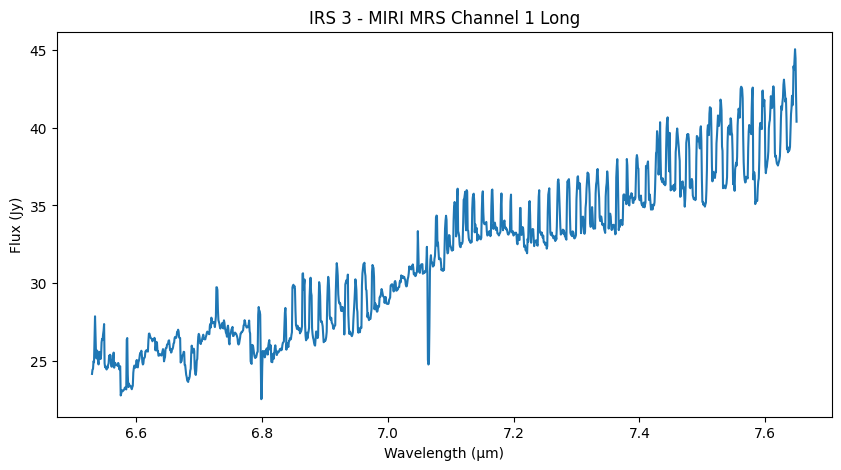

In [24]:
wavelength = data["WAVELENGTH"]
flux = data["FLUX"]

plt.figure(figsize=(10, 5))
plt.plot(wavelength, flux)
plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux (Jy)")
plt.title("IRS 3 - MIRI MRS Channel 1 Long")
plt.show()

In [25]:
# error + dq exploration
flux_error = data["FLUX_ERROR"]
dq = data["DQ"]

print("First 10 flux errors:")
print(flux_error[:10])

print("\nUnique DQ values:")
print(dq[:10])
print(np.unique(dq))

print("Number of wavelength points:", len(wavelength))
print("Number with DQ != 0:", np.sum(dq != 0))
print("Number of NaN flux values:", np.sum(np.isnan(flux)))

First 10 flux errors:
[0.06217377 0.06503519 0.06893103 0.06519116 0.05823265 0.06810778
 0.08159663 0.06937705 0.0761233  0.06636242]

Unique DQ values:
[0 0 0 0 0 0 0 0 0 0]
[0]
Number of wavelength points: 1400
Number with DQ != 0: 0
Number of NaN flux values: 0


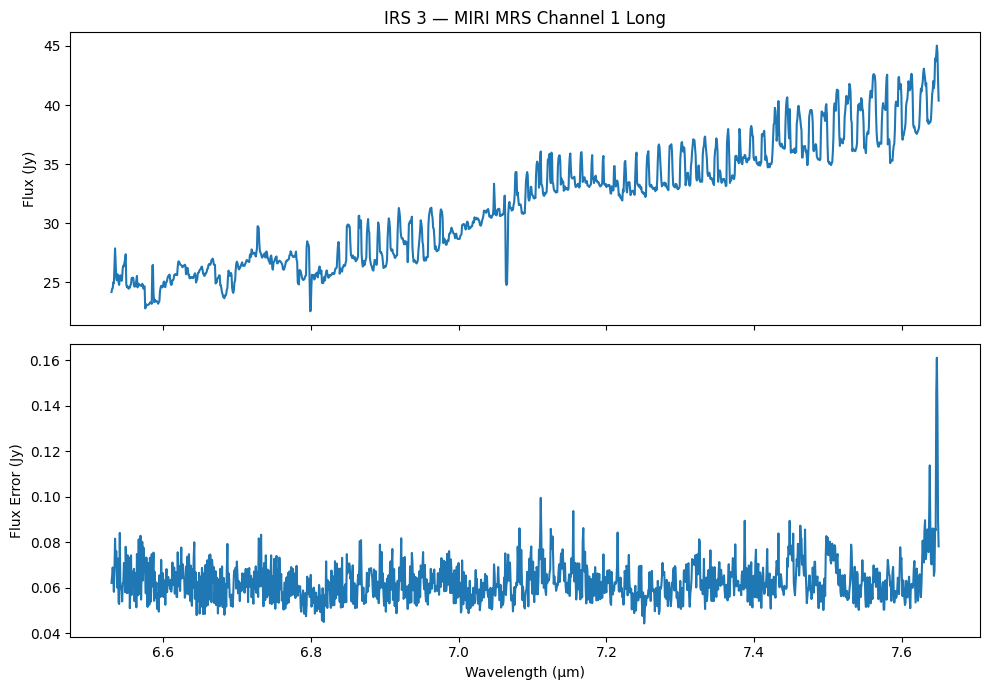

In [26]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Spectrum
ax[0].plot(wavelength, flux)
ax[0].set_ylabel("Flux (Jy)")
ax[0].set_title("IRS 3 — MIRI MRS Channel 1 Long")

# Flux uncertainty
ax[1].plot(wavelength, flux_error)
ax[1].set_xlabel("Wavelength (µm)")
ax[1].set_ylabel("Flux Error (Jy)")

plt.tight_layout()
plt.show()

### Channel 1 Long — Initial Analysis

The Channel 1 Long spectrum contains 1,400 wavelength measurements from approximately 6.5–7.7 μm. The overall flux increases with wavelength, but the spectrum also contains many narrow spikes and dips. At this stage, these features cannot be assumed to be either real spectral features or data-quality problems.

All DQ values are 0 and there are no NaN flux values, meaning none of these points are flagged as problematic in the extracted spectrum. The flux uncertainty remains relatively small (~0.05–0.08 Jy) across most of the spectrum, although it increases near the longest wavelengths. The visible spikes do not generally correspond to similarly large increases in uncertainty.

This provides an interesting QC question: unusual-looking features may be present even when the extracted data contain no DQ flags or obviously large uncertainties. More MIRI channels should be examined before determining whether these features are instrumental, processing-related, or astrophysical.

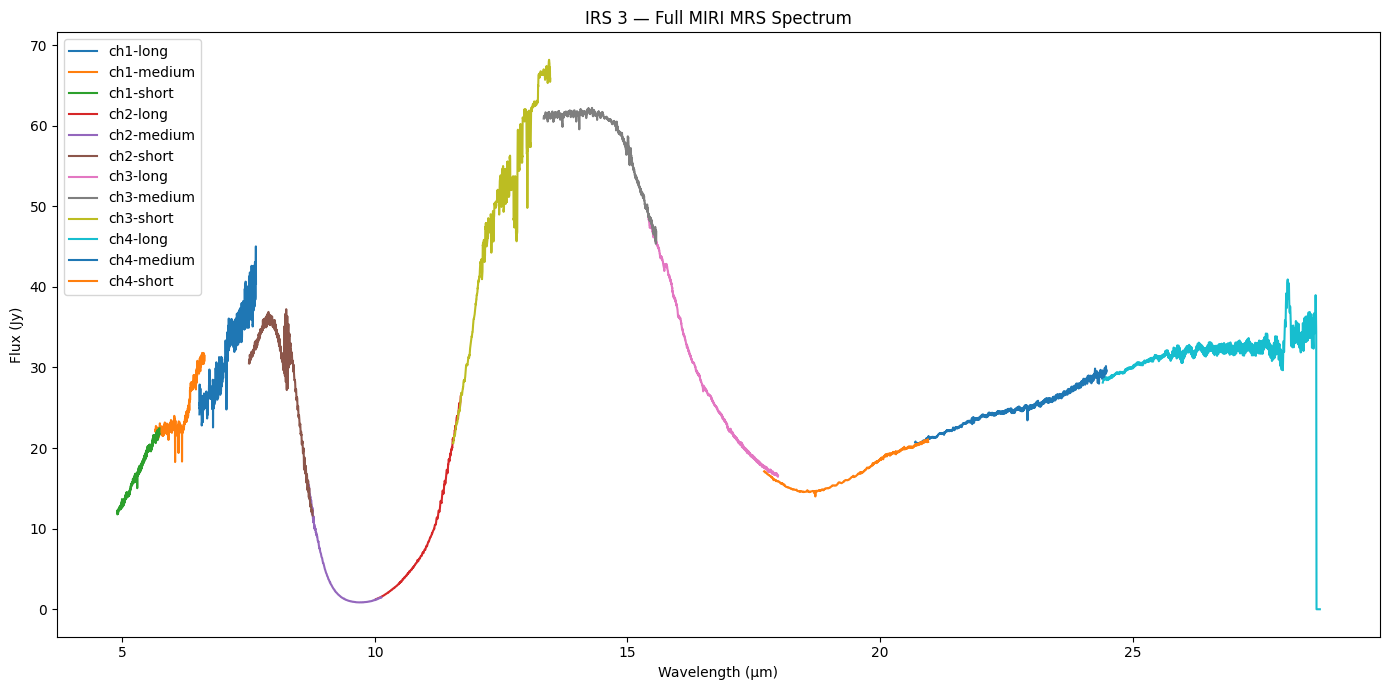

In [27]:
# all 12 x1d files
plt.figure(figsize=(14,7))

for file in x1d_files:
    with fits.open(file) as hdul:
        data = hdul["EXTRACT1D"].data
        wavelength = data["WAVELENGTH"]
        flux = data["FLUX"]

        # shorten filename
        label = file.stem.replace(
            "jw01266-o009_t002_miri_", ""
        ).replace("_x1d", "")
        
        plt.plot(wavelength, flux, label=label)

plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux (Jy)")
plt.title("IRS 3 — Full MIRI MRS Spectrum")

plt.legend()
plt.tight_layout()
plt.show()

### Full MIRI MRS Spectrum — Initial Exploration

The 12 X1D products collectively cover approximately 5–28 μm and represent the short, medium, and long sub-bands of MIRI MRS Channels 1–4. Most neighboring segments overlap and form a relatively continuous spectrum.

Several regions contain unusual structure, including narrow spikes and dips, particularly at shorter wavelengths and near some segment boundaries. These features cannot yet be classified as instrumental artifacts or real astrophysical features. For example, the large decrease in flux near 10 μm corresponds to a known silicate absorption feature discussed in the IRS 3 paper, demonstrating that unusual-looking structure is not necessarily a data-quality problem.

Future exploration should compare these features with uncertainties, data-quality flags, channel boundaries, and known MIRI artifacts before determining which quality issues the project will target.

In [28]:
x1d_file = data_dir / "jw01266-o009_t002_miri_ch1-long_x1d.fits"

with fits.open(x1d_file) as hdul:
    x1d_data = hdul["EXTRACT1D"].data
    
    wavelength_x1d = x1d_data["WAVELENGTH"]
    flux_x1d = x1d_data["FLUX"]
    error_x1d = x1d_data["FLUX_ERROR"]

In [29]:
s3d_file = data_dir / "jw01266-o009_t002_miri_ch1-long_s3d.fits"

with fits.open(s3d_file) as hdul:
    hdul.info()
    cube = hdul["SCI"].data
    error_cube = hdul["ERR"].data
    dq_cube = hdul["DQ"].data
    print(hdul["WCS-TABLE"].columns)
    print(hdul["WCS-TABLE"].data)

print("Science cube shape:", cube.shape)
print("Error cube shape:", error_cube.shape)
print("DQ cube shape:", dq_cube.shape)

Filename: data/IRS3/jw01266-o009_t002_miri_ch1-long_s3d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     284   ()      
  1  SCI           1 ImageHDU        89   (45, 41, 1400)   float32   
  2  ERR           1 ImageHDU        12   (45, 41, 1400)   float32   
  3  DQ            1 ImageHDU        12   (45, 41, 1400)   int32 (rescales to uint32)   
  4  WMAP          1 ImageHDU        10   (45, 41, 1400)   float32   
  5  WCS-TABLE     1 BinTableHDU     13   1R x 1C   [1400E]   
  6  HDRTAB        1 BinTableHDU    498   4R x 244C   [23A, 5A, 3A, 46A, 7A, 13A, 4A, 5A, 5A, 7A, 13A, 4A, L, D, D, 32A, 49A, 65A, 22A, 3A, 20A, 10A, 12A, 23A, 23A, 26A, 11A, 5A, 3A, 3A, 2A, 1A, 2A, 1A, L, 35A, 14A, 2A, 26A, 20A, 27A, 10A, K, L, L, L, L, 7A, 7A, 5A, D, D, D, D, D, D, D, D, 5A, 4A, 11A, 2A, 4A, 4A, 3A, K, 5A, 7A, D, D, D, D, D, D, D, D, D, 6A, K, K, K, K, K, K, K, K, K, D, D, D, D, D, D, D, D, D, K, K, L, L, K, K, D, 4A, K, K, K, K, K, K, 7A, K

(1400,)
[6.5304003 6.5312004 6.532     6.5328    6.5336003]

Index: 700
Wavelength: 7.0904 um


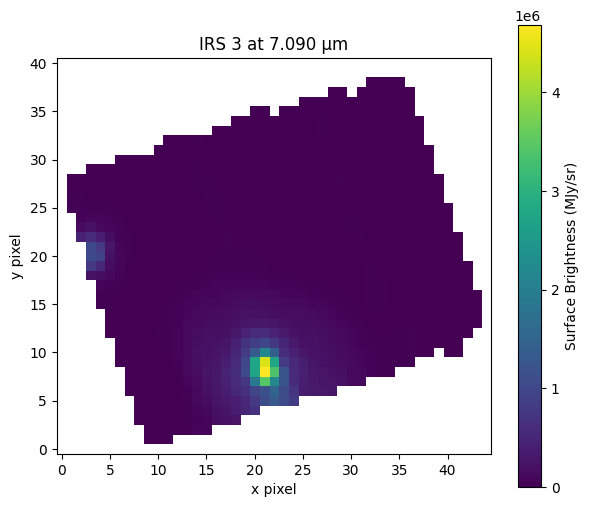

[6.53040021 6.53120021 6.53200021 6.53280021 6.53360021]
[6.5304003 6.5312004 6.532     6.5328    6.5336003]
True


In [30]:
# pull wavelength array out in a clean form
with fits.open(s3d_file) as hdul:
    wavelengths_3d = hdul["WCS-TABLE"].data["wavelength"][0].flatten()

print(wavelengths_3d.shape)
print(wavelengths_3d[:5])
print()

# at one specific wavelength, where is that IR light coming from
middle = len(wavelengths_3d) // 2

print("Index:", middle)
print("Wavelength:", wavelengths_3d[middle], "um")

plt.figure(figsize=(7, 6))
plt.imshow(cube[middle, :, :], origin="lower")
plt.colorbar(label="Surface Brightness (MJy/sr)")
plt.title(f"IRS 3 at {wavelengths_3d[middle]:.3f} μm")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.show()

# check
print(wavelength_x1d[:5])
print(wavelengths_3d[:5])

print(np.allclose(wavelength_x1d, wavelengths_3d))

Largest changes in flux:
Index: 397 | Wavelength: 6.848000201774994 | Change: 2.8704462517485823
Index: 1061 | Wavelength: 7.379200188355753 | Change: 2.897552029203503
Index: 334 | Wavelength: 6.797600203048205 | Change: 2.9171205614608553
Index: 68 | Wavelength: 6.584800208423985 | Change: 3.1896640766132514
Index: 1336 | Wavelength: 7.599200182798086 | Change: 3.2154571910894916
Index: 417 | Wavelength: 6.8640002013708 | Change: 3.3802171117477364
Index: 670 | Wavelength: 7.066400196257746 | Change: 3.5054590935961656
Index: 1040 | Wavelength: 7.362400188780157 | Change: 3.595023403785497
Index: 666 | Wavelength: 7.063200196338585 | Change: 5.381315101231603
Index: 1312 | Wavelength: 7.5800001832831185 | Change: 5.892281944217892


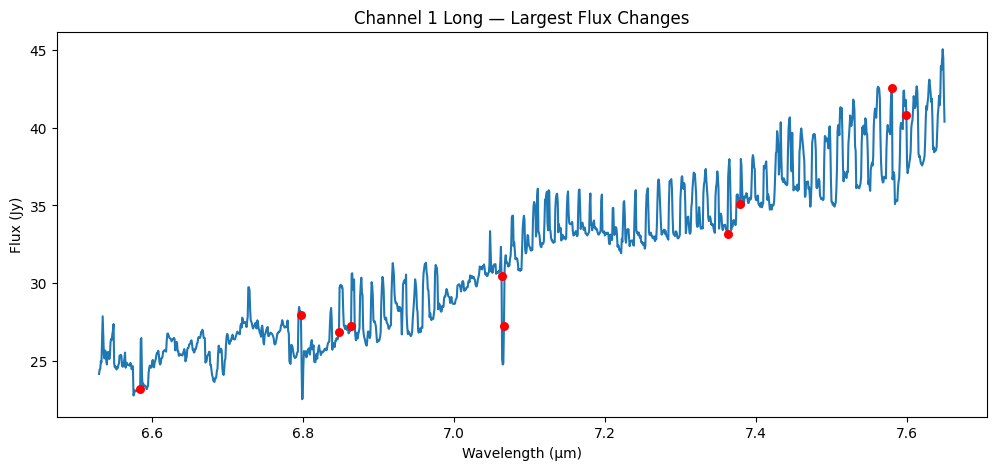

In [31]:
# find spectral peaks
flux_difference = np.abs(np.diff(flux_x1d))
peak_indices = np.where(flux > 21)[0]

print("Largest changes in flux:")
largest_changes = np.argsort(flux_difference)[-10:]

for index in largest_changes:
    print(
        "Index:", index,
        "| Wavelength:", wavelength_x1d[index],
        "| Change:", flux_difference[index]
    )

plt.figure(figsize=(12, 5))

# full channel 1 long spectrum
plt.plot(wavelength_x1d, flux_x1d)

# mark the locations of the 10 largest adjacent changes
plt.scatter(
    wavelength_x1d[largest_changes],
    flux_x1d[largest_changes],
    color="red",
    s=30,
    zorder=3
)

plt.xlabel("Wavelength (μm)")
plt.ylabel("Flux (Jy)")
plt.title("Channel 1 Long — Largest Flux Changes")
plt.show()

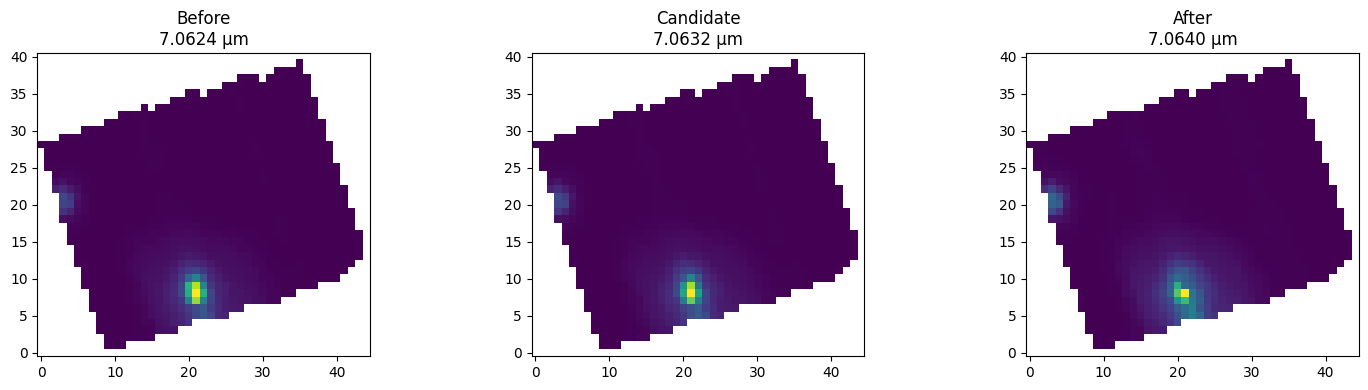

Index: 660 | Wavelength: 7.0584 | Flux: 30.66
Index: 661 | Wavelength: 7.0592 | Flux: 30.78
Index: 662 | Wavelength: 7.06 | Flux: 30.74
Index: 663 | Wavelength: 7.0608 | Flux: 30.78
Index: 664 | Wavelength: 7.0616 | Flux: 31.39
Index: 665 | Wavelength: 7.0624 | Flux: 32.34
Index: 666 | Wavelength: 7.0632 | Flux: 30.47
Index: 667 | Wavelength: 7.064 | Flux: 25.08
Index: 668 | Wavelength: 7.0648 | Flux: 24.79
Index: 669 | Wavelength: 7.0656 | Flux: 24.86
Index: 670 | Wavelength: 7.0664 | Flux: 27.23
Index: 671 | Wavelength: 7.0672 | Flux: 30.74
Index: 672 | Wavelength: 7.068 | Flux: 31.53
Index: 673 | Wavelength: 7.0688 | Flux: 31.8
Index: 674 | Wavelength: 7.0696 | Flux: 31.31


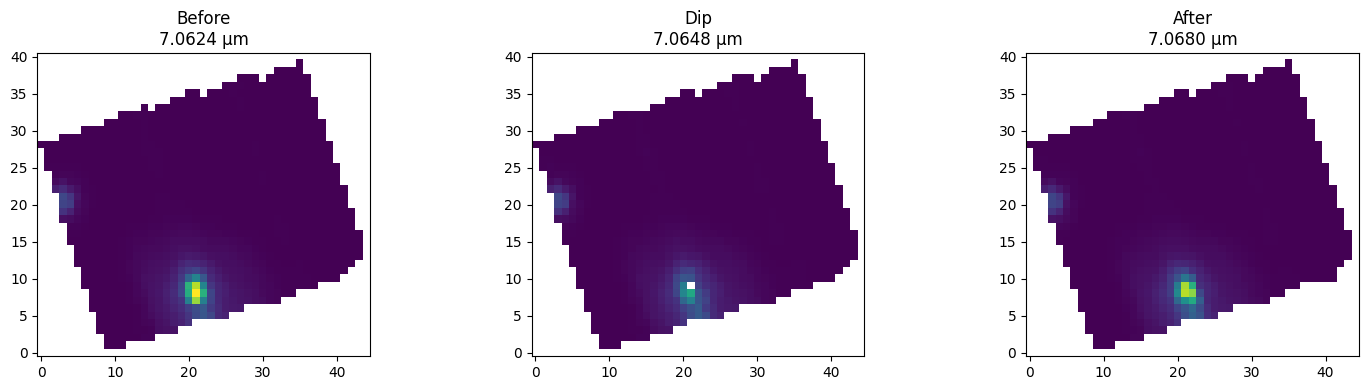

In [32]:
# looking at index 666
candidate_index = 666

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(cube[candidate_index - 1, :, :], origin="lower")
ax[0].set_title(
    f"Before\n{wavelengths_3d[candidate_index - 1]:.4f} μm"
)

ax[1].imshow(cube[candidate_index, :, :], origin="lower")
ax[1].set_title(
    f"Candidate\n{wavelengths_3d[candidate_index]:.4f} μm"
)

ax[2].imshow(cube[candidate_index + 1, :, :], origin="lower")
ax[2].set_title(
    f"After\n{wavelengths_3d[candidate_index + 1]:.4f} μm"
)

plt.tight_layout()
plt.show()

# after index is higher than candidate -> find actual point
for i in range(660, 675):
    print(
        "Index:", i,
        "| Wavelength:", round(wavelength_x1d[i], 4),
        "| Flux:", round(flux_x1d[i], 2)
    )

# before 665, candidate 668, after 672
candidate_index = 668
before_index = 665
after_index = 672

# find shared color scale
images = [
    cube[before_index, :, :],
    cube[candidate_index, :, :],
    cube[after_index, :, :]
]

vmin = np.nanmin(images)
vmax = np.nanmax(images)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(
    cube[before_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
ax[0].set_title(
    f"Before\n{wavelengths_3d[before_index]:.4f} μm"
)

ax[1].imshow(
    cube[candidate_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
ax[1].set_title(
    f"Dip\n{wavelengths_3d[candidate_index]:.4f} μm"
)

ax[2].imshow(
    cube[after_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
ax[2].set_title(
    f"After\n{wavelengths_3d[after_index]:.4f} μm"
)

plt.tight_layout()
plt.show()

In [33]:
# closer look at central source during dip
index = 668

# small region around the source
region = cube[index, 5:13, 18:26]

print("Central source values:")
print(region)

print("Number of NaNs:", np.isnan(region).sum())

# check data-quality flags in the same region
print("DQ values:")
print(dq_cube[index, 5:13, 18:26])

# look at suspicious cube
y = 9
x = 21

for i in range(660, 675):
    print(
        "Index:", i,
        "| Wavelength:", round(wavelengths_3d[i], 4),
        "| Value:", cube[i, y, x],
        "| DQ:", dq_cube[i, y, x]
    )

Central source values:
[[ 387993.94  539773.94  785591.3  1157101.4  1398481.9  1119582.1
   587694.44  482341.88]
 [ 495143.75  619941.3   954684.94 1204876.4  1399494.5   847910.8
   594580.44  378697.  ]
 [ 565102.1   730440.3  1655018.2  2180280.   1287811.2   969930.5
   540114.94  380057.12]
 [ 609292.9  1026582.1  2270020.   2971192.8  1246087.6   860125.25
   524689.44  414455.84]
 [ 554306.   1068463.   2108196.2         nan  928822.8   647702.06
   509929.53  375534.12]
 [ 487595.84  986758.25 1312906.6  1248795.2   770766.    552109.5
   415911.88  287454.25]
 [ 394873.34  674783.1   915272.7   956828.4   637163.44  462197.2
   309398.25  224703.11]
 [ 289909.78  474638.56  592538.3   513716.56  458574.22  323909.56
   212960.36  191873.81]]
Number of NaNs: 1
DQ values:
[[  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0 513   0   0   0   0]
 [  0   0   0   0   0   0   0   0

## Observation
The narrow dip near 7.065 $\micro$m coincides with a dramatic decrease in surface brightness at the central source position in the S3D cube. At the center of the dip there's two NaN values. These NaN's have DQ=513 (DO_NOT_USE + NON_SCIENCE). JWST documentation notes that NaN data near a spectral trace can produce dips in extracted spectra during cube building. The cause of the missing input hasn't been determined, but saturation is one possiblity that I will investigate using some earlier pipeline products.

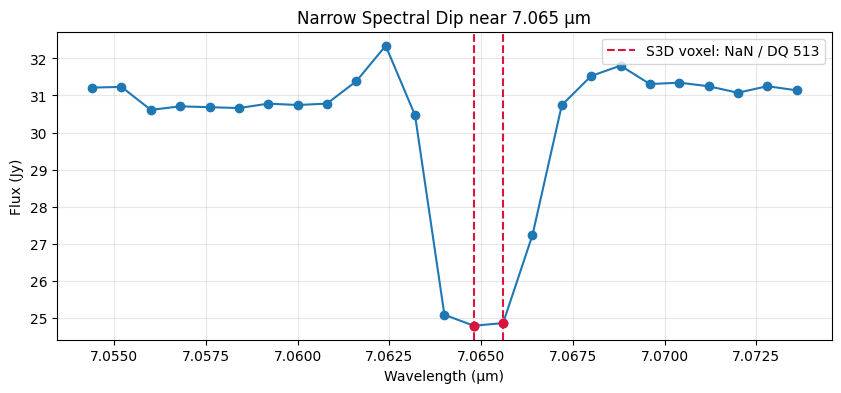

In [34]:
# zoom in on dip
start = 655
stop = 680

plt.figure(figsize=(10, 4))

plt.plot(
    wavelength_x1d[start:stop],
    flux_x1d[start:stop],
    marker="o"
)

plt.scatter(
    wavelength_x1d[[668, 669]],
    flux_x1d[[668, 669]],
    color="crimson",
    zorder=5
)

# mark wavelengths where the central S3D is NaN / DQ 513
plt.axvline(
    wavelengths_3d[668],
    color="crimson",
    linestyle="--",
    label="S3D voxel: NaN / DQ 513"
)

plt.axvline(
    wavelengths_3d[669],
    color="crimson",
    linestyle="--"
)

plt.legend()

plt.xlabel("Wavelength (μm)")
plt.ylabel("Flux (Jy)")
plt.title("Narrow Spectral Dip near 7.065 μm")

plt.grid(alpha=0.3)
plt.show()

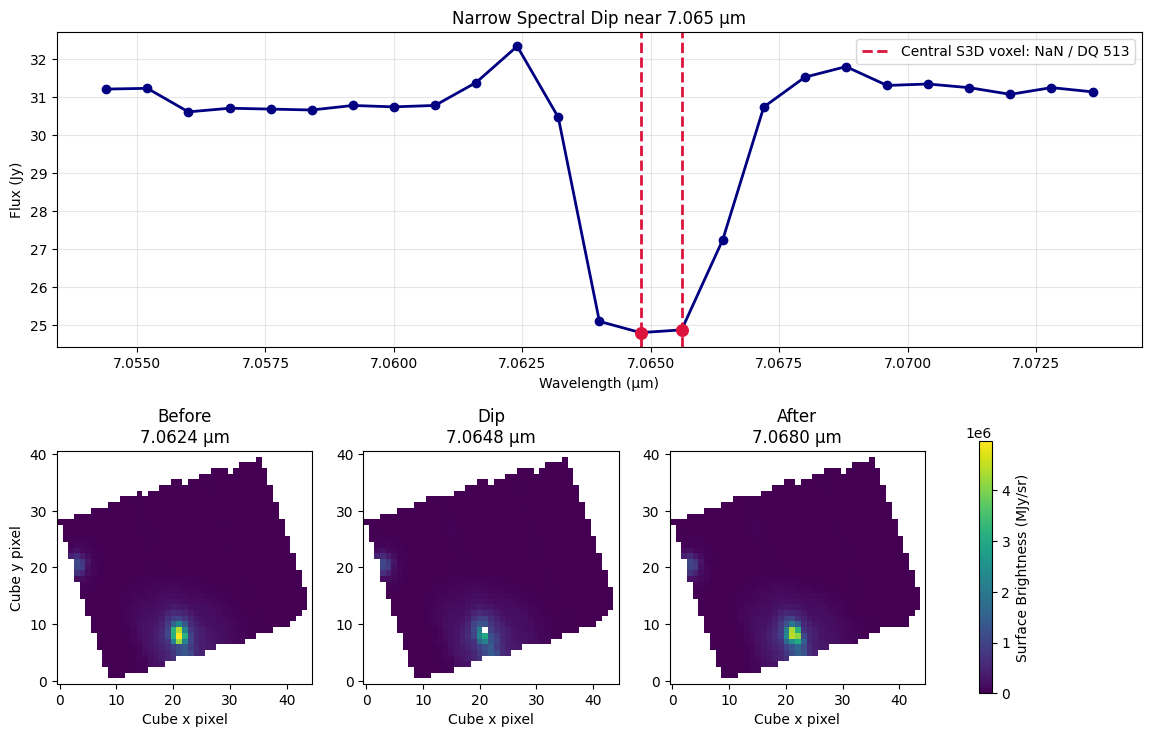

In [35]:
# Indices used for the spatial comparison
before_index = 665
dip_index = 668
after_index = 672

# Same color scale for all three S3D images
images = [
    cube[before_index, :, :],
    cube[dip_index, :, :],
    cube[after_index, :, :]
]

vmin = np.nanmin(images)
vmax = np.nanmax(images)

# Create the figure
fig = plt.figure(figsize=(14, 9))

# Layout: spectrum across the top, three images underneath
gs = fig.add_gridspec(2, 3)

ax_spectrum = fig.add_subplot(gs[0, :])
ax_before = fig.add_subplot(gs[1, 0])
ax_dip = fig.add_subplot(gs[1, 1])
ax_after = fig.add_subplot(gs[1, 2])


# ----- TOP: X1D SPECTRUM -----

ax_spectrum.plot(
    wavelength_x1d[start:stop],
    flux_x1d[start:stop],
    marker="o",
    color="navy",
    linewidth=2
)

# Highlight wavelengths where central S3D voxel is NaN
ax_spectrum.scatter(
    wavelength_x1d[[668, 669]],
    flux_x1d[[668, 669]],
    color="crimson",
    s=70,
    zorder=5
)

ax_spectrum.axvline(
    wavelengths_3d[668],
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Central S3D voxel: NaN / DQ 513"
)

ax_spectrum.axvline(
    wavelengths_3d[669],
    color="crimson",
    linestyle="--",
    linewidth=2
)

ax_spectrum.set_xlabel("Wavelength (μm)")
ax_spectrum.set_ylabel("Flux (Jy)")
ax_spectrum.set_title("Narrow Spectral Dip near 7.065 μm")
ax_spectrum.grid(alpha=0.3)
ax_spectrum.legend()


# ----- BOTTOM: S3D IMAGES -----

im = ax_before.imshow(
    cube[before_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

ax_before.set_title(
    f"Before\n{wavelengths_3d[before_index]:.4f} μm"
)

ax_dip.imshow(
    cube[dip_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

ax_dip.set_title(
    f"Dip\n{wavelengths_3d[dip_index]:.4f} μm"
)

ax_after.imshow(
    cube[after_index, :, :],
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

ax_after.set_title(
    f"After\n{wavelengths_3d[after_index]:.4f} μm"
)

# One colorbar for all three images
cbar = fig.colorbar(
    im,
    ax=[ax_before, ax_dip, ax_after],
    shrink=0.8
)

cbar.set_label("Surface Brightness (MJy/sr)")
for ax in [ax_before, ax_dip, ax_after]:
    ax.set_xlabel("Cube x pixel")

ax_before.set_ylabel("Cube y pixel")

plt.show()

### Investigation of Narrow Spectral Dip near 7.065 μm

A narrow dip was identified in the Channel 1 Long X1D spectrum near 7.065 μm. 
The flux decreases from approximately 31–32 Jy to about 25 Jy before returning 
to its previous level.

To investigate the feature, I compared the corresponding wavelength slices in 
the S3D spectral cube. At the location of the central source, the surface 
brightness decreases substantially during the dip. At indices 668 and 669 
(7.0648 and 7.0656 μm), the central voxel contains NaN values and has a data 
quality (DQ) value of 513, indicating that these voxels should not be used as 
valid science data.

The missing S3D data occur at the same wavelengths as the bottom of the dip in 
the extracted X1D spectrum, suggesting that the spectral feature is associated 
with missing or unusable data near the bright source. However, the Stage 3 
products alone do not identify the original cause of the invalid data. In 
particular, this is not enough evidence to conclude that the feature is caused 
by saturation.

**Next step:** Examine an earlier-stage pipeline product for this observation to 
determine why the affected data were flagged as unusable. This will help 
determine whether the original problem was saturation or another detector/data 
quality issue and which pipeline correction may be appropriate.

## Tracing the 7.065 μm Dip Through the JWST Pipeline

### Stage 2: Inspecting Calibrated Detector Data

In [36]:
cal_file = data_dir / "jw01266009001_04101_00001_mirifushort_cal.fits"

with fits.open(cal_file) as hdul:
    hdul.info()

Filename: data/IRS3/jw01266009001_04101_00001_mirifushort_cal.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     269   ()      
  1  SCI           1 ImageHDU        70   (1032, 1024)   float32   
  2  ERR           1 ImageHDU        10   (1032, 1024)   float32   
  3  DQ            1 ImageHDU        11   (1032, 1024)   int32 (rescales to uint32)   
  4  VAR_POISSON    1 ImageHDU         9   (1032, 1024)   float32   
  5  VAR_RNOISE    1 ImageHDU         9   (1032, 1024)   float32   
  6  VAR_FLAT      1 ImageHDU         9   (1032, 1024)   float32   
  7  ASDF          1 BinTableHDU     11   1R x 1C   [8878592B]   


In [37]:
with fits.open(cal_file) as hdul:
    cal_data = hdul["SCI"].data
    cal_dq = hdul["DQ"].data

print("Science data shape:", cal_data.shape)
print("DQ data shape:", cal_dq.shape)
print("Unique DQ values:", np.unique(cal_dq))

Science data shape: (1024, 1032)
DQ data shape: (1024, 1032)
Unique DQ values: [         0          1          2          3          4          5
          6          7       4097       4099     262145     262147
     262149     262151     266241     266243  268435458  268435459
  268435462  268435463  268439555  268697603  268697607  268701699
 2147745793 2147745795 2147745797 2147745799]


In [38]:
# Count pixels with each basic DQ flag
total_pixels = cal_dq.size

do_not_use = np.count_nonzero((cal_dq & 1) != 0)
saturated = np.count_nonzero((cal_dq & 2) != 0)
jump_detected = np.count_nonzero((cal_dq & 4) != 0)

print("Total detector pixels:", total_pixels)
print("DO_NOT_USE pixels:", do_not_use)
print("SATURATED pixels:", saturated)
print("JUMP_DET pixels:", jump_detected)

print("Saturated percentage:", 100 * saturated / total_pixels)

Total detector pixels: 1056768
DO_NOT_USE pixels: 353978
SATURATED pixels: 13277
JUMP_DET pixels: 676272
Saturated percentage: 1.256377937257752


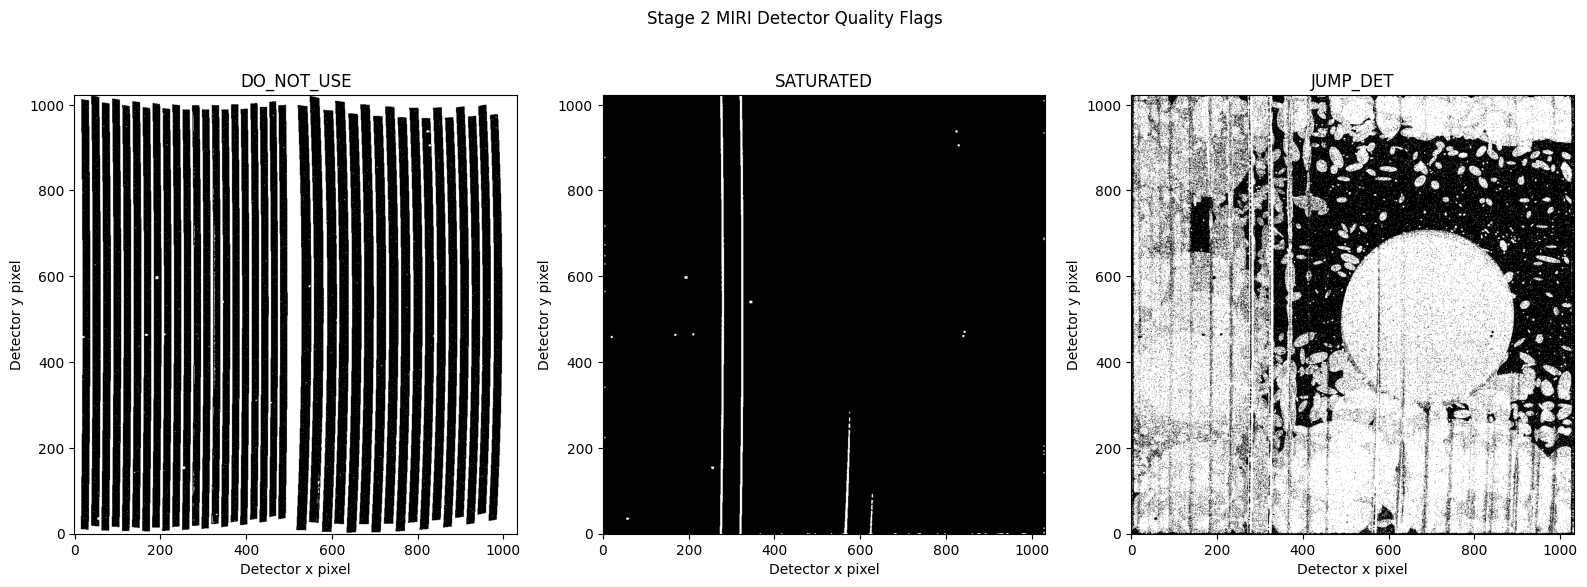

In [43]:
# Create masks for each quality flag
do_not_use_mask = (cal_dq & 1) != 0
saturation_mask = (cal_dq & 2) != 0
jump_mask = (cal_dq & 4) != 0

# Set up three side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

flags = [
    ("DO_NOT_USE", do_not_use_mask),
    ("SATURATED", saturation_mask),
    ("JUMP_DET", jump_mask)
]

for ax, (name, mask) in zip(axes, flags):
    ax.imshow(mask, origin="lower", cmap="gray", vmin=0, vmax=1)

    ax.set_title(name)
    ax.set_xlabel("Detector x pixel")
    ax.set_ylabel("Detector y pixel")

plt.suptitle("Stage 2 MIRI Detector Quality Flags")
plt.tight_layout()
plt.show()

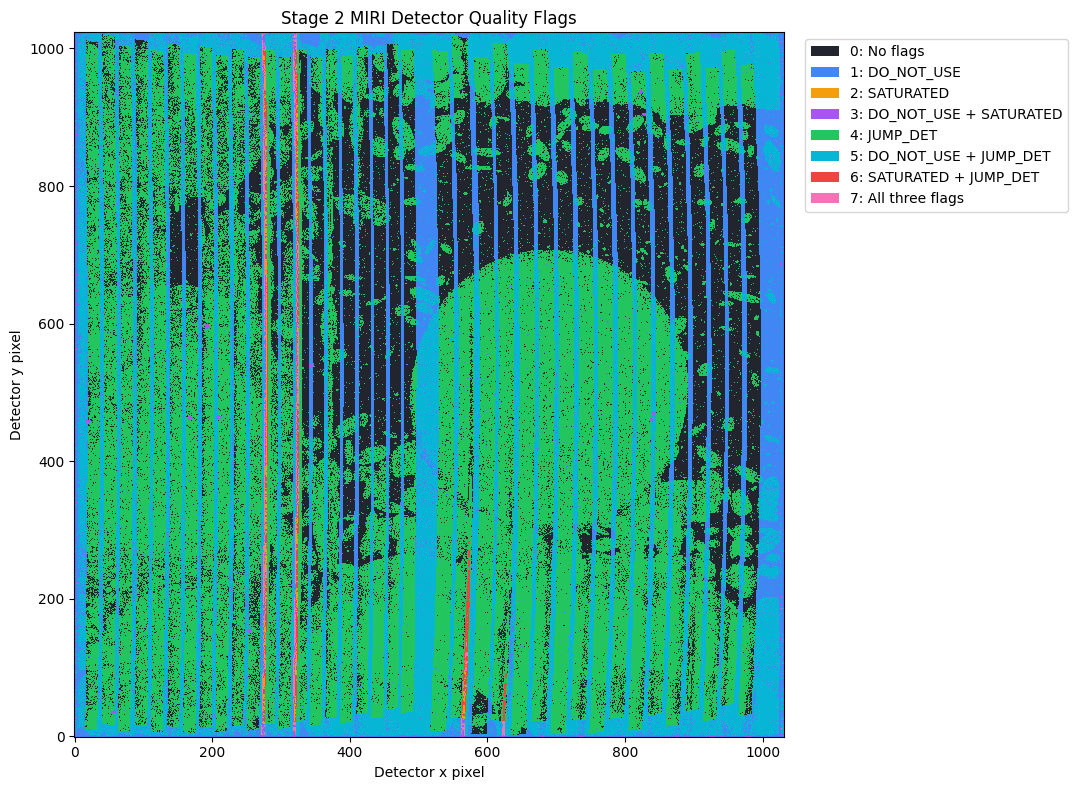

0: No flags: 247,931 pixels (23.46%)
1: DO_NOT_USE: 127,711 pixels (12.09%)
2: SATURATED: 2,341 pixels (0.22%)
3: DO_NOT_USE + SATURATED: 2,513 pixels (0.24%)
4: JUMP_DET: 448,118 pixels (42.40%)
5: DO_NOT_USE + JUMP_DET: 219,731 pixels (20.79%)
6: SATURATED + JUMP_DET: 4,400 pixels (0.42%)
7: All three flags: 4,023 pixels (0.38%)


In [47]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Extract each flag from the DQ bitmask
do_not_use = (cal_dq & 1) != 0
saturated = (cal_dq & 2) != 0
jump_det = (cal_dq & 4) != 0

# Create a map of the 8 possible combinations
combined = (
    do_not_use.astype(int)
    + 2 * saturated.astype(int)
    + 4 * jump_det.astype(int)
)

# Colors for each combination (0 through 7)
colors = [
    "#22252d",  # 0: No flags
    "#4285f4",  # 1: DO_NOT_USE
    "#f59e0b",  # 2: SATURATED
    "#a855f7",  # 3: DO_NOT_USE + SATURATED
    "#22c55e",  # 4: JUMP_DET
    "#06b6d4",  # 5: DO_NOT_USE + JUMP_DET
    "#ef4444",  # 6: SATURATED + JUMP_DET
    "#f472b6"   # 7: All three
]

labels = [
    "No flags",
    "DO_NOT_USE",
    "SATURATED",
    "DO_NOT_USE + SATURATED",
    "JUMP_DET",
    "DO_NOT_USE + JUMP_DET",
    "SATURATED + JUMP_DET",
    "All three flags"
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 8.5, 1), cmap.N)

fig, ax = plt.subplots(figsize=(11, 8))

ax.imshow(combined, origin="lower",
          cmap=cmap, norm=norm,
          interpolation="nearest")

ax.set_title("Stage 2 MIRI Detector Quality Flags")
ax.set_xlabel("Detector x pixel")
ax.set_ylabel("Detector y pixel")

legend = [
    Patch(facecolor=colors[i], label=f"{i}: {labels[i]}")
    for i in range(8)
]

ax.legend(handles=legend, loc="upper left",
          bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

# How many pixels have overlapping flags
for i, label in enumerate(labels):
    count = np.count_nonzero(combined == i)
    percent = 100 * count / combined.size

    print(f"{i}: {label}: {count:,} pixels ({percent:.2f}%)")

In [45]:
print("dq shape:", np.shape(dq))
print("combined shape:", np.shape(combined))

print("do_not_use shape:", np.shape(do_not_use))
print("saturated shape:", np.shape(saturated))
print("jump_det shape:", np.shape(jump_det))

dq shape: (1400,)
combined shape: (1400,)
do_not_use shape: (1400,)
saturated shape: (1400,)
jump_det shape: (1400,)


## Stage 2 Saturation Investigation

To investigate the spectral dip near 7.065 μm, I downloaded an earlier-stage JWST pipeline product (mirifushort_cal.fits). This file contains calibrated detector measurements and data quality (DQ) flags, allowing me to investigate problems that may have occurred before the final spectral cube was constructed.

### JWST bitmask quality flags key

- 0 -> no quality flags
- 1 -> DO_NOT_USE
- 2 -> SATURATED
- 3 -> DO_NOT_USE + SATURATED
- 4 -> JUMP_DET
- 5 -> DO_NOT_USE + JUMP_DET
- 6 -> SATURATED + JUMP_DET
- 7 -> DO_NOT_USE + SATURATED + JUMP_DET

### Distribution of Quality Flags

| Flag | # of Pixels | % of Detector |
| --- | --- | --- |
| DO_NOT_USE | 353,978 | 33.50% |
| SATURATED | 13,277 | 1.26% |
| JUMP_DET | 676,272 | 63.99% |

These can overlap because pixels can contian multiple flags.

### Visualizing Quality Flags
- **JUMP_DET is the most common flag.** Approximately 42.4% of detector pixels have only the the JUMP_DET flag, while another 20.79% have both JUMP_DET and DO_NOT_USE.
- **The flags have distinct spatial distributions.** The combined map shows repeated vertical structures, a large rounded region dominated by JUMP_DET, and smaller localized regions containing saturation flags.

**Next:** 
- Install jwst and gwcs packages.
- Find where 7.065 $\micro m$ falls on the detector.
- Compare those locations with the combined quality flag map.
- Investigate if those flagged regions could affect the extracted spectrum.